# Lab Exercise 4 — Topic Modelling of BBC News with Latent Dirichlet Allocation
**Advance NLP (AML23702) · Department of AIML**

**Aim.** Apply **Latent Dirichlet Allocation (LDA)** to a collection of 2,225 BBC News articles and interpret the topics it discovers. The same LDA model is fitted with two inference methods:
* a **probabilistic (variational Bayes)** method, using scikit-learn's `LatentDirichletAllocation`;
* a **sampling-based** method, using a **collapsed Gibbs sampler** written from scratch in this notebook.

**Pipeline:** raw articles → cleaning, lemmatisation, stop-word and part-of-speech filtering, phrase detection → document-term matrix → choice of the number of topics *K* (topic coherence, held-out perplexity, topic diversity) → LDA by variational Bayes and by Gibbs sampling → topic-word lists and interpretation → comparison of the two methods and with the BBC's own section labels.

| Expected outcome (lab sheet) | Where in this notebook |
|---|---|
| Preprocess text data | §2 preprocessing (saved to `outputs/preprocessed_corpus.csv`) |
| Build a document-term representation | §3 document-term matrix (saved to `outputs/dtm.npz`, `outputs/vocabulary.txt`) |
| Train an LDA model | §5 choosing *K*, §6 variational Bayes LDA, §7 collapsed Gibbs sampling LDA |
| Interpret topic-word distributions | §6 topic-word lists and labels, §8 topics vs. BBC sections, §9 stability, §10 *K* = 5 |
| Deliverables: preprocessed corpus, LDA output, topic-word lists, report, visualisations | `outputs/` folder, figures in every section, §11 findings |

### How to run
1. Put `bbc_news.csv` in a folder called `data` next to this notebook. If it is missing, the notebook downloads the original BBC dataset (Greene & Cunningham, 2006) from `mlg.ucd.ie` and builds the file itself.
2. `Kernel → Restart & Run All`. The whole notebook takes about 10–12 minutes on a laptop. Most of that time goes to spaCy preprocessing (about 1.5 min), choosing *K* (21 models, about 5 min) and the Gibbs sampler (about 3 min).
3. All random seeds are fixed, so a re-run gives the same topics.

In [1]:
# 0. Setup: install anything missing (safe to re-run)
import importlib.util, subprocess, sys
PACKAGES = {"sklearn": "scikit-learn", "spacy": "spacy", "pandas": "pandas", "matplotlib": "matplotlib", "scipy": "scipy"}
missing = [pip for mod, pip in PACKAGES.items() if importlib.util.find_spec(mod) is None]
if missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing])
import spacy
if not spacy.util.is_package("en_core_web_sm"):
    subprocess.check_call([sys.executable, "-m", "spacy", "download", "en_core_web_sm"])
print("environment ready")

environment ready


In [2]:
import io, json, math, random, re, time, zipfile
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy.sparse as sp
from scipy.optimize import linear_sum_assignment
from scipy.special import gammaln
from sklearn.decomposition import LatentDirichletAllocation
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score
from IPython.display import display

pd.set_option("display.max_colwidth", 120)
pd.set_option("display.width", 160)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "font.size": 9})
DATA, OUT = Path("data"), Path("outputs")
DATA.mkdir(exist_ok=True); OUT.mkdir(exist_ok=True)
SEED = 0
random.seed(SEED); np.random.seed(SEED)
print("scikit-learn", __import__("sklearn").__version__, "| spaCy", spacy.__version__, "| numpy", np.__version__)

scikit-learn 1.9.1 | spaCy 3.8.7 | numpy 2.5.3


## 1. The document collection: BBC News

The **BBC News dataset** (Greene & Cunningham, ICML 2006) contains **2,225 articles** from the BBC News website, published in 2004–2005. Each article was filed by the BBC under one of five sections: *business, entertainment, politics, sport, tech*. In every file, the first line is the headline and the rest is the article text.

The section labels are **not used to train LDA**, which is unsupervised. They are used only afterwards, to check whether the discovered topics line up with the way the BBC organised its news (§8).

The dataset contains some articles more than once, and these are removed before modelling: a duplicate counts its words twice and pulls topics towards repeated stories.

In [3]:
CSV = DATA / "bbc_news.csv"
if not CSV.exists():   # build the CSV from the original zip (bbc/<section>/<nnn>.txt)
    import requests
    raw = requests.get("http://mlg.ucd.ie/files/datasets/bbc-fulltext.zip", timeout=120).content
    rows = []
    with zipfile.ZipFile(io.BytesIO(raw)) as z:
        for name in sorted(z.namelist()):
            m = re.match(r"bbc/(\w+)/(\d+)\.txt$", name)
            if not m:
                continue
            text = z.read(name).decode("latin-1")
            lines = [l.strip() for l in text.strip().split("\n")]
            rows.append({"doc_id": f"{m.group(1)}/{m.group(2)}.txt", "category": m.group(1), "title": lines[0],
                         "text": " ".join(l for l in lines[1:] if l)})
    pd.DataFrame(rows).to_csv(CSV, index=False)

raw_df = pd.read_csv(CSV)
corpus = raw_df.drop_duplicates("text").reset_index(drop=True)
corpus["n_words"] = corpus.text.str.split().str.len()
print(f"{len(raw_df)} articles loaded, {len(raw_df) - len(corpus)} exact duplicates removed -> {len(corpus)} documents")
display(pd.DataFrame({"articles": corpus.category.value_counts(),
                      "median words": corpus.groupby("category").n_words.median().astype(int)}).T)
corpus[["doc_id", "category", "title"]].head(3)

2225 articles loaded, 136 exact duplicates removed -> 2089 documents


category,business,entertainment,politics,sport,tech
articles,500,366,394,492,337
median words,292,256,436,282,461


,doc_id,category,title
0,business/001.txt,business,Ad sales boost Time Warner profit
1,business/002.txt,business,Dollar gains on Greenspan speech
2,business/003.txt,business,Yukos unit buyer faces loan claim


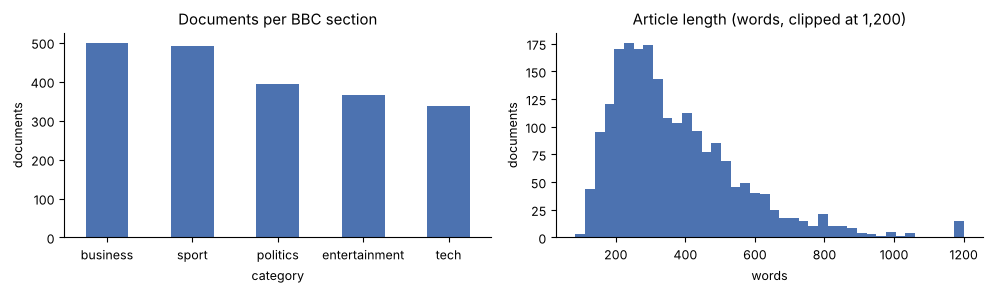

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3))
corpus.category.value_counts().plot.bar(ax=ax[0], color="#4c72b0", rot=0)
ax[0].set_title("Documents per BBC section"); ax[0].set_ylabel("documents")
ax[1].hist(corpus.n_words.clip(upper=1200), bins=40, color="#4c72b0")
ax[1].set_title("Article length (words, clipped at 1,200)"); ax[1].set_xlabel("words"); ax[1].set_ylabel("documents")
plt.tight_layout(); fig.savefig(OUT / "corpus_overview.png", dpi=200, bbox_inches="tight"); plt.show()

## 2. Preprocessing

LDA treats a document as a **bag of words**, so preprocessing decides which words become the "vocabulary" of the topics. Each step, and the reason for it:

| Step | Tool | Why |
|---|---|---|
| Headline and body joined | pandas | the headline is the most informative sentence |
| Tokenisation, part-of-speech tagging, lemmatisation | spaCy `en_core_web_sm` | merges *shares/shared/sharing* into *share*, so one topic word stands for all its forms |
| Keep only nouns, proper nouns, adjectives and verbs | spaCy POS tags | topics are carried by content words; pronouns, numbers and function words only add noise |
| Remove stop words, tokens shorter than 3 letters, non-alphabetic tokens | spaCy stop list | numbers, punctuation and *the, of, and* appear in every document |
| Remove **news-generic words** (*say, year, people, new, time, …*) | custom list | these words occur in every BBC section; left in, they top every topic and make topics look alike |
| Join frequent two-word phrases (*prime_minister*, *mobile_phone*) | own NPMI phrase detector | a phrase means more than its parts: *prime* and *minister* separately are vague |

Phrases are found from pairs of content words that are adjacent in the original text. A pair is joined when it occurs at least 20 times and its **normalised pointwise mutual information** is at least 0.5, meaning the two words occur together far more often than chance.

In [5]:
nlp = spacy.load("en_core_web_sm", disable=["parser", "ner"])
KEEP_POS = {"NOUN", "PROPN", "ADJ", "VERB"}
NEWS_GENERIC = {"say", "mr", "year", "people", "good", "new", "time", "include", "tell", "use", "make", "go", "get",
                "take", "come", "want", "know", "think", "look", "add", "way", "number", "week", "month", "day",
                "expect", "work", "give", "find", "need", "see", "like", "lot", "thing", "try", "show", "put", "mean",
                "set", "end", "big", "bad", "great", "long", "high", "old", "early", "late", "recent", "far", "second",
                "report", "accord", "can", "will"}

def content_lemmas(doc):
    """Lemmas of content words; None marks a gap, so phrases are only formed from words that were adjacent."""
    out = []
    for tok in doc:
        lem = tok.lemma_.lower()
        if tok.pos_ in KEEP_POS and tok.is_alpha and len(lem) > 2 and not tok.is_stop and lem not in NEWS_GENERIC:
            out.append(lem)
        elif out and out[-1] is not None:
            out.append(None)
    return out

t0 = time.time()
lemma_seqs = [content_lemmas(d) for d in nlp.pipe((h + ". " + b for h, b in zip(corpus.title, corpus.text)), batch_size=64)]
print(f"spaCy processed {len(lemma_seqs)} documents in {time.time() - t0:.0f} s")

spaCy processed 2089 documents in 90 s


In [6]:
# ---- phrase detection with NPMI over adjacent content-word pairs ----
uni = Counter(w for s in lemma_seqs for w in s if w)
pairs = Counter((a, b) for s in lemma_seqs for a, b in zip(s, s[1:]) if a and b)
n_tok, n_pair = sum(uni.values()), sum(pairs.values())

def npmi_pair(a, b):
    p_ab, p_a, p_b = pairs[(a, b)] / n_pair, uni[a] / n_tok, uni[b] / n_tok
    return math.log(p_ab / (p_a * p_b)) / -math.log(p_ab)

PHRASES = {(a, b) for (a, b), c in pairs.items() if c >= 20 and npmi_pair(a, b) >= 0.5}

def merge_phrases(seq):
    out, i = [], 0
    while i < len(seq):
        if seq[i] and i + 1 < len(seq) and (seq[i], seq[i + 1]) in PHRASES:
            out.append(seq[i] + "_" + seq[i + 1]); i += 2
        else:
            if seq[i]:
                out.append(seq[i])
            i += 1
    return out

tokens = [merge_phrases(s) for s in lemma_seqs]
corpus["tokens"] = [" ".join(t) for t in tokens]
corpus["n_tokens"] = [len(t) for t in tokens]
top_phr = sorted(PHRASES, key=lambda p: -pairs[p])
print(f"{len(PHRASES)} phrases joined; most frequent:", ", ".join(f"{a}_{b} ({pairs[(a, b)]})" for a, b in top_phr[:14]))
print(f"tokens per document after preprocessing: median {int(np.median(corpus.n_tokens))} "
      f"(from a median of {int(corpus.n_words.median())} words)")

215 phrases joined; most frequent: prime_minister (304), chief_executive (197), tony_blair (174), mobile_phone (164), bbc_news (162), general_election (161), michael_howard (117), gordon_brown (108), bbc_radio (105), home_secretary (104), interest_rate (99), lib_dems (98), liberal_democrats (87), world_cup (87)
tokens per document after preprocessing: median 140 (from a median of 324 words)


In [7]:
ex = corpus.iloc[0]
print("ORIGINAL :", (ex.title + ". " + ex.text)[:420], "...\n")
print("TOKENS   :", " ".join(tokens[0][:60]), "...")
corpus[["doc_id", "category", "title", "tokens"]].to_csv(OUT / "preprocessed_corpus.csv", index=False)
print("\nsaved outputs/preprocessed_corpus.csv")

ORIGINAL : Ad sales boost Time Warner profit. Quarterly profits at US media giant TimeWarner jumped 76% to $1.13bn (£600m) for the three months to December, from $639m year-earlier. The firm, which is now one of the biggest investors in Google, benefited from sales of high-speed internet connections and higher advert sales. TimeWarner said fourth quarter sales rose 2% to $11.1bn from $10.9bn. Its profits were buoyed by one-off  ...

TOKENS   : sale boost warner profit quarterly profit medium giant timewarner jump december firm investor google benefit sale speed internet connection advert sale timewarner fourth_quarter sale rise profit buoy gain offset profit dip warner bros user aol warner friday own search engine google internet business aol mixed fortune lose subscriber fourth_quarter profit low precede quarter company aol underlying profit exceptional item rise ...

saved outputs/preprocessed_corpus.csv


## 3. Document-term representation

LDA's input is a **document-term matrix** *X*: one row per document, one column per vocabulary word, and each cell holds the count of that word in that document. Raw counts are used, not TF-IDF, because LDA is a generative model of word counts.

The vocabulary is pruned on document frequency (df):
* `min_df = 5`: a word that appears in fewer than 5 documents cannot define a topic, and it inflates the vocabulary;
* `max_df = 0.5`: a word that appears in more than half of all documents does not separate one topic from another.

**Held-out split.** 10% of the documents (stratified by section) are set aside as a **test set** and are never used to fit a model. The models are judged on them with *document-completion perplexity*: each test document is split into two halves; its topic mixture is estimated from the first half; then the model predicts the words of the second half. Lower perplexity means better prediction of unseen text.

In [8]:
vectorizer = CountVectorizer(analyzer=str.split, min_df=5, max_df=0.5)
X_all = vectorizer.fit_transform(corpus.tokens)
vocab = np.array(vectorizer.get_feature_names_out())
V = len(vocab)

rng = np.random.default_rng(SEED)
test_idx = np.sort(np.concatenate([rng.choice(g.index.values, size=round(0.1 * len(g)), replace=False)
                                   for _, g in corpus.groupby("category")]))
train_idx = np.setdiff1d(np.arange(len(corpus)), test_idx)
X_train, X_test = X_all[train_idx], X_all[test_idx]

# document completion: alternate tokens of each test document go to the 'observed' and 'held-out' halves
word_index = vectorizer.vocabulary_
test_ids = [[word_index[w] for w in tokens[i] if w in word_index] for i in test_idx]
obs_half = [ids[0::2] for ids in test_ids]
held_half = [ids[1::2] for ids in test_ids]
X_obs = sp.csr_matrix((np.ones(sum(map(len, obs_half))),
                       (np.repeat(np.arange(len(obs_half)), [len(h) for h in obs_half]), np.concatenate(obs_half))),
                      shape=(len(obs_half), V))

stats = {"documents": X_all.shape[0], "train documents": len(train_idx), "test documents": len(test_idx),
         "vocabulary size": V, "tokens in matrix": int(X_all.sum()),
         "density (non-zero cells)": f"{X_all.nnz / (X_all.shape[0] * V):.2%}"}
display(pd.Series(stats, name="document-term matrix").to_frame())
sp.save_npz(OUT / "dtm.npz", X_all)
(OUT / "vocabulary.txt").write_text("\n".join(vocab))

freq = np.asarray(X_all.sum(0)).ravel()
print("20 most frequent vocabulary words:", ", ".join(f"{vocab[i]} ({freq[i]})" for i in np.argsort(-freq)[:20]))
print("saved outputs/dtm.npz and outputs/vocabulary.txt")

,document-term matrix
documents,2089
train documents,1880
test documents,209
vocabulary size,6433
tokens in matrix,300573
density (non-zero cells),1.52%


20 most frequent vocabulary words: win (1402), game (1277), play (1098), government (1091), world (1063), company (1061), film (1038), firm (874), plan (777), country (751), player (698), market (685), labour (681), sale (663), service (640), music (621), help (611), start (603), group (599), rise (591)
saved outputs/dtm.npz and outputs/vocabulary.txt


## 4. How topics are evaluated

LDA has no "correct answer", so three standard measures are combined:

* **Topic coherence (NPMI).** For the 10 top words of a topic, average the normalised pointwise mutual information of every word pair. Probabilities are measured as document co-occurrence in the whole corpus. The range is −1 to 1; higher means the top words really occur together, which correlates well with human judgements of topic quality (Röder et al., 2015).
* **Held-out perplexity** (document completion, see §3): how well the model predicts words in unseen documents.
* **Topic diversity.** The share of unique words among all topics' top-10 words. A value of 1 means no two topics share a top word; a low value means duplicate topics.

The **same LDA model** is used throughout, with symmetric Dirichlet priors **α = 0.1** (document-topic) and **β = 0.01** (topic-word). The two inference methods therefore differ only in *how* they estimate the posterior, not in *what* they estimate.

In [9]:
ALPHA, BETA = 0.1, 0.01
B_bin = (X_all > 0).astype(np.float64).tocsc()
DF, N_DOCS = np.asarray(B_bin.sum(0)).ravel(), X_all.shape[0]

def npmi_coherence(top_ids):
    """Mean NPMI over all pairs of the given word ids (document co-occurrence on the full corpus)."""
    sub = B_bin[:, top_ids]
    co = (sub.T @ sub).toarray()
    vals = []
    for i in range(len(top_ids)):
        for j in range(i + 1, len(top_ids)):
            if co[i, j] == 0:
                vals.append(-1.0); continue
            p_ij = co[i, j] / N_DOCS
            p_i, p_j = DF[top_ids[i]] / N_DOCS, DF[top_ids[j]] / N_DOCS
            vals.append(math.log(p_ij / (p_i * p_j)) / -math.log(p_ij))
    return float(np.mean(vals))

def top_ids(phi, n=10):
    return [list(np.argsort(-row)[:n]) for row in phi]

def topic_quality(phi):
    tops = top_ids(phi)
    coh = [npmi_coherence(t) for t in tops]
    return {"npmi": float(np.mean(coh)), "npmi per topic": coh,
            "diversity": len({w for t in tops for w in t}) / (10 * len(tops))}

def completion_perplexity(phi, theta_obs):
    """phi: K x V topic-word probabilities; theta_obs: topic mixtures estimated from the observed halves."""
    ll, n = 0.0, 0
    for d, ids in enumerate(held_half):
        p = theta_obs[d] @ phi[:, ids]
        ll += np.log(p).sum(); n += len(ids)
    return float(np.exp(-ll / n))

def normalise(m):
    return m / m.sum(axis=1, keepdims=True)
print("evaluation functions ready")

evaluation functions ready


## 5. Choosing the number of topics *K* (variational Bayes)

**LDA as a generative model.** Each topic *k* is a probability distribution φₖ over the vocabulary, with φₖ ~ Dirichlet(β). Each document *d* has a topic mixture θ_d ~ Dirichlet(α). Every word of the document is produced by first picking a topic z ~ θ_d and then a word w ~ φ_z. Training inverts this process: given only the words, it infers the posterior over φ, θ and z. The exact posterior is intractable, so it has to be approximated.

**Variational Bayes (VB)** is the *probabilistic, optimisation-based* approximation (Blei, Ng & Jordan, 2003; Hoffman et al., 2010). It picks the closest member of a simpler, fully factorised family of distributions by maximising a lower bound on the likelihood (the ELBO). scikit-learn's `LatentDirichletAllocation` implements it; `learning_method="batch"` uses all documents in each update.

*K* is not learnt by LDA, so it is chosen here by fitting models for each value of *K* on the training documents and scoring them. VB finds a *local* optimum that depends on the random initialisation, so every *K* is fitted with **three seeds** and the scores are averaged.

In [10]:
K_GRID, SWEEP_SEEDS = [4, 5, 6, 7, 8, 10, 12], [0, 1, 2]
sweep, models = [], {}
t_all = time.time()
for K in K_GRID:
    for s in SWEEP_SEEDS:
        m = LatentDirichletAllocation(n_components=K, doc_topic_prior=ALPHA, topic_word_prior=BETA,
                                      learning_method="batch", max_iter=30, random_state=s).fit(X_train)
        phi = normalise(m.components_)
        q = topic_quality(phi)
        sweep.append({"K": K, "seed": s, "npmi": q["npmi"], "diversity": q["diversity"],
                      "perplexity": completion_perplexity(phi, m.transform(X_obs))})
        if s == SEED:
            models[K] = m
runs = pd.DataFrame(sweep)
K_SEL = runs.groupby("K").agg(**{"NPMI mean": ("npmi", "mean"), "NPMI min": ("npmi", "min"), "NPMI max": ("npmi", "max"),
                                 "topic diversity": ("diversity", "mean"), "held-out perplexity": ("perplexity", "mean")}).round(4).reset_index()
K_SEL["held-out perplexity"] = K_SEL["held-out perplexity"].round(1)
K_SEL.to_csv(OUT / "k_selection.csv", index=False)
K_FINAL = int(K_SEL.loc[K_SEL["NPMI mean"].idxmax(), "K"])
print(f"{len(runs)} models fitted in {time.time() - t_all:.0f} s (each K with seeds {SWEEP_SEEDS}; mean, min and max over seeds)")
display(K_SEL)
print("K with the highest coherence:", K_FINAL)

21 models fitted in 292 s (each K with seeds [0, 1, 2]; mean, min and max over seeds)


,K,NPMI mean,NPMI min,NPMI max,topic diversity,held-out perplexity
0,4,0.1792,0.1587,0.2060,0.9000,2160.0
1,5,0.2042,0.1637,0.2486,0.9200,2084.4
2,6,0.2359,0.2227,0.2590,0.9278,1986.3
3,7,0.2225,0.2011,0.2468,0.8952,1931.0
4,8,0.2209,0.2008,0.2438,0.8917,1922.0
5,10,0.1944,0.1692,0.2138,0.8667,1877.8
6,12,0.2055,0.1929,0.2130,0.8611,1834.2


K with the highest coherence: 6


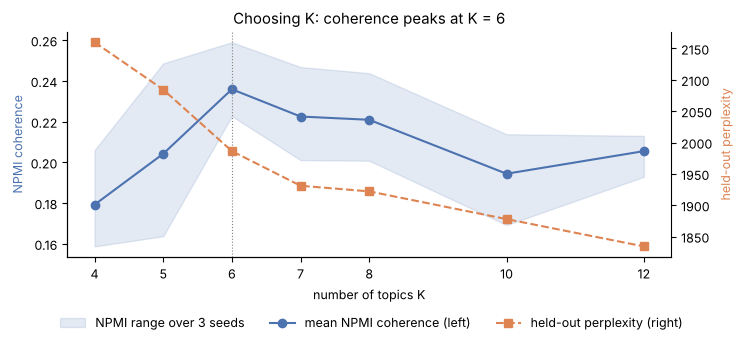

In [11]:
fig, ax1 = plt.subplots(figsize=(7.5, 3.2))
ax1.fill_between(K_SEL.K, K_SEL["NPMI min"], K_SEL["NPMI max"], color="#4c72b0", alpha=0.15, label="NPMI range over 3 seeds")
ax1.plot(K_SEL.K, K_SEL["NPMI mean"], "o-", color="#4c72b0", label="mean NPMI coherence (left)")
ax1.set_xlabel("number of topics K"); ax1.set_ylabel("NPMI coherence", color="#4c72b0"); ax1.set_xticks(K_GRID)
ax2 = ax1.twinx(); ax2.spines["right"].set_visible(True)
ax2.plot(K_SEL.K, K_SEL["held-out perplexity"], "s--", color="#dd8452", label="held-out perplexity (right)")
ax2.set_ylabel("held-out perplexity", color="#dd8452")
ax1.axvline(K_FINAL, color="grey", lw=0.8, ls=":")
ax1.set_title(f"Choosing K: coherence peaks at K = {K_FINAL}")
fig.legend(loc="lower center", ncol=3, bbox_to_anchor=(0.5, -0.08), frameon=False)
plt.tight_layout(); fig.savefig(OUT / "k_selection.png", dpi=200, bbox_inches="tight"); plt.show()

**Reading the curves.** Coherence measures whether each topic's top words belong together; perplexity measures how well the model predicts held-out words. The two often disagree. Perplexity keeps improving as *K* grows, because a model with more topics fits more of the detail in each document, but that detail is not necessarily what a person would call a topic (Chang et al., 2009). *K* is therefore chosen by **coherence**, and diversity is checked to make sure there are no duplicate topics.

## 6. The final variational Bayes model

The model with the chosen *K* is refitted with more iterations (`max_iter = 100`) so that it converges. Each topic is described in two ways:
* its **top words by probability** φₖ(w): the most frequent words of the topic;
* its **top words by relevance**, with λ = 0.6 (Sievert & Shirley, 2014): relevance = λ·log φₖ(w) + (1 − λ)·log(φₖ(w) / p(w)). This penalises words that are frequent everywhere, so the words that make a topic distinctive come forward.

Topics get a human-readable label. The label comes from a small list of cue words checked against each topic's top 10 words, so it follows the words if a re-run reorders the topics. If no cue list matches at least two top words, the label is simply the topic's top three words.

In [12]:
t0 = time.time()
vb = LatentDirichletAllocation(n_components=K_FINAL, doc_topic_prior=ALPHA, topic_word_prior=BETA,
                               learning_method="batch", max_iter=100, random_state=SEED).fit(X_train)
VB_SECONDS = time.time() - t0
phi_vb = normalise(vb.components_)
theta_vb = vb.transform(X_train)
p_w = np.asarray(X_train.sum(0)).ravel() / X_train.sum()

CUES = {
    "Sport": {"win", "play", "player", "team", "match", "game", "coach", "injury", "champion", "england", "season"},
    "Entertainment: film, music & TV": {"film", "music", "award", "star", "band", "album", "show", "singer", "actor", "tv", "director"},
    "Film & awards": {"film", "actor", "oscar", "award", "movie", "actress", "director", "festival", "star"},
    "UK politics & elections": {"labour", "election", "blair", "party", "tory", "minister", "howard", "prime_minister", "vote"},
    "Football": {"club", "chelsea", "football", "league", "manager", "arsenal", "liverpool", "united", "cup"},
    "Economy & markets": {"economy", "growth", "bank", "rate", "price", "market", "rise", "inflation", "dollar"},
    "Internet & mobile tech": {"mobile", "phone", "user", "net", "broadband", "software", "computer", "internet", "site", "network"},
    "Music": {"music", "song", "band", "album", "chart", "singer", "single", "record"},
    "Rugby": {"rugby", "wales", "ireland", "scotland", "half", "six_nations", "try", "coach"},
    "Tennis & athletics": {"open", "champion", "seed", "tennis", "race", "olympic", "title", "final", "athletics"},
    "Law, courts & civil liberties": {"law", "court", "police", "legal", "lord", "rule", "right", "case", "charge"},
    "Games & consumer electronics": {"dvd", "console", "xbox", "sony", "nintendo", "gadget", "device", "video", "gamer"},
    "Companies & deals": {"company", "firm", "deal", "profit", "share", "chief_executive", "sale", "buy"},
    "TV & media": {"show", "series", "channel", "programme", "bbc", "viewer", "comedy", "tv"},
}

def label_topics(phi):
    labels = []
    for ids in top_ids(phi):
        words = set(vocab[ids])
        best = max(CUES, key=lambda c: len(CUES[c] & words))
        lab = best if len(CUES[best] & words) >= 2 else " / ".join(vocab[ids[:3]])
        labels.append(lab if lab not in labels else f"{lab} ({vocab[ids[0]]})")
    return labels

def relevance_top(phi, k, n=10, lam=0.6):
    rel = lam * np.log(phi[k]) + (1 - lam) * np.log(phi[k] / p_w)
    return vocab[np.argsort(-rel)[:n]]

labels_vb = label_topics(phi_vb)
q_vb = topic_quality(phi_vb)
prev_vb = theta_vb.mean(0)
topic_table = pd.DataFrame({
    "topic": range(K_FINAL), "label": labels_vb, "share of corpus": np.round(prev_vb, 3),
    "NPMI": np.round(q_vb["npmi per topic"], 3),
    "top words by probability (φ)": [", ".join(f"{vocab[i]} {phi_vb[k, i]:.3f}" for i in ids[:8]) for k, ids in enumerate(top_ids(phi_vb))],
    "top words by relevance (λ=0.6)": [", ".join(relevance_top(phi_vb, k, 8)) for k in range(K_FINAL)]})
print(f"VB LDA, K = {K_FINAL}: fitted in {VB_SECONDS:.0f} s, mean NPMI {q_vb['npmi']:.3f}, diversity {q_vb['diversity']:.2f}")
topic_table.sort_values("share of corpus", ascending=False)

VB LDA, K = 6: fitted in 35 s, mean NPMI 0.259, diversity 0.93


,topic,label,share of corpus,NPMI,top words by probability (φ),top words by relevance (λ=0.6)
2,2,Economy & markets,0.213,0.249,"company 0.012, firm 0.010, market 0.009, rise 0.008, sale 0.008, share 0.007, bank 0.007, analyst 0.006","company, market, firm, rise, bank, sale, analyst, share"
1,1,Sport,0.202,0.249,"win 0.015, play 0.013, game 0.012, player 0.010, england 0.009, team 0.007, club 0.007, match 0.007","win, play, england, player, game, match, club, team"
3,3,"Entertainment: film, music & TV",0.174,0.157,"film 0.021, game 0.011, award 0.010, star 0.010, win 0.010, music 0.008, play 0.007, world 0.005","film, award, star, game, music, actor, win, album"
0,0,UK politics & elections,0.162,0.334,"government 0.014, labour 0.013, party 0.010, election 0.009, plan 0.008, blair 0.007, country 0.007, brown 0.006","labour, government, party, election, blair, brown, prime_minister, plan"
4,4,Internet & mobile tech,0.125,0.375,"technology 0.012, service 0.009, mobile 0.008, user 0.008, network 0.008, computer 0.008, phone 0.007, net 0.007","technology, mobile, user, computer, network, phone, site, service"
5,5,"Law, courts & civil liberties",0.124,0.191,"law 0.010, court 0.009, case 0.008, police 0.007, charge 0.006, rule 0.006, decision 0.005, ban 0.005","law, court, case, police, ban, charge, trial, rule"


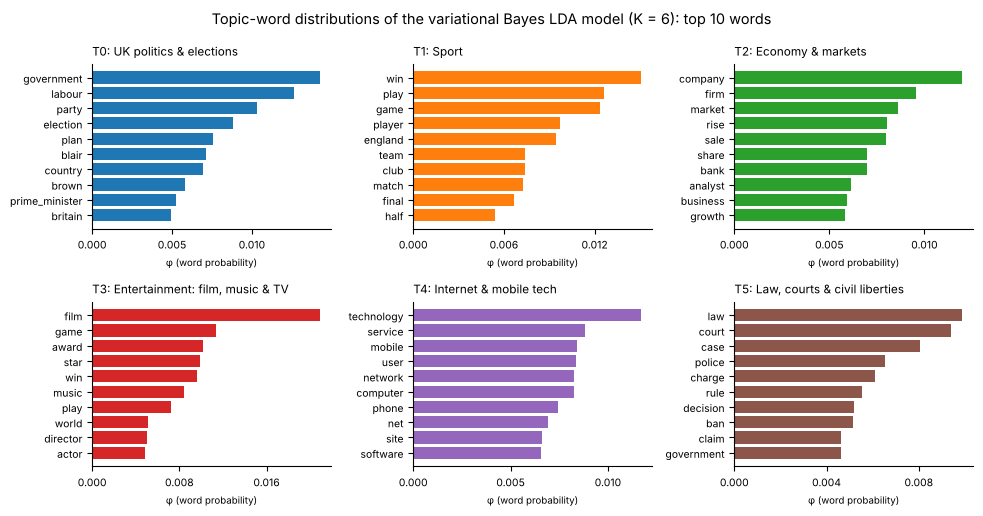

In [13]:
cols = 3 if K_FINAL <= 9 else 5
rows_ = math.ceil(K_FINAL / cols)
fig, axes = plt.subplots(rows_, cols, figsize=(3.3 * cols, 2.6 * rows_))
for k, ax in zip(range(K_FINAL), axes.ravel()):
    ids = np.argsort(-phi_vb[k])[:10][::-1]
    ax.barh(vocab[ids], phi_vb[k, ids], color=plt.cm.tab10(k % 10))
    ax.set_title(f"T{k}: {labels_vb[k]}", fontsize=8.5, loc="left"); ax.tick_params(labelsize=7.5)
    ax.set_xlabel("φ (word probability)", fontsize=7); ax.xaxis.set_major_locator(plt.MaxNLocator(3))
for ax in axes.ravel()[K_FINAL:]:
    ax.axis("off")
fig.suptitle(f"Topic-word distributions of the variational Bayes LDA model (K = {K_FINAL}): top 10 words", fontsize=10.5)
plt.tight_layout(); fig.savefig(OUT / "topics_vb.png", dpi=200, bbox_inches="tight"); plt.show()

In [14]:
tr = corpus.iloc[train_idx].reset_index(drop=True)
rows = []
for k in np.argsort(-prev_vb):
    for d in np.argsort(-theta_vb[:, k])[:2]:
        rows.append({"topic": f"T{k} {labels_vb[k]}", "θ": round(theta_vb[d, k], 3), "BBC section": tr.category[d], "headline": tr.title[d]})
print("Most representative headlines per topic (highest θ):")
display(pd.DataFrame(rows))

mixed = [(d, np.argsort(-theta_vb[d])[:2]) for d in range(len(tr)) if np.sort(theta_vb[d])[-2] >= 0.3]
print(f"\n{len(mixed)} of {len(tr)} training documents ({len(mixed)/len(tr):.0%}) mix two topics with θ ≥ 0.30 each, e.g.:")
for d, (a, b) in mixed[:6]:
    print(f"  [{tr.category[d]:>13}] {tr.title[d][:60]:<60}  {labels_vb[a]} {theta_vb[d, a]:.2f} + {labels_vb[b]} {theta_vb[d, b]:.2f}")

pd.DataFrame([{"topic": k, "label": labels_vb[k], "rank": r + 1, "word": vocab[i], "probability": round(phi_vb[k, i], 5)}
              for k, ids in enumerate(top_ids(phi_vb, 20)) for r, i in enumerate(ids)]).to_csv(OUT / "topic_words_vb.csv", index=False)
pd.concat([tr[["doc_id", "category", "title"]], pd.DataFrame(np.round(theta_vb, 4), columns=[f"T{k}" for k in range(K_FINAL)])],
          axis=1).to_csv(OUT / "doc_topics_vb.csv", index=False)
import joblib; joblib.dump({"model": vb, "vectorizer": vectorizer}, OUT / "lda_vb_model.joblib")
print("\nsaved outputs/topic_words_vb.csv, outputs/doc_topics_vb.csv, outputs/lda_vb_model.joblib")

Most representative headlines per topic (highest θ):


,topic,θ,BBC section,headline
0,T2 Economy & markets,0.998,business,Air China in $1bn London listing
1,T2 Economy & markets,0.998,business,Oil prices reach three-month low
2,T1 Sport,0.999,sport,Henman to face Saulnier test
3,T1 Sport,0.998,sport,Federer joins all-time greats
4,"T3 Entertainment: film, music & TV",0.998,entertainment,The Producers scoops stage awards
5,"T3 Entertainment: film, music & TV",0.998,entertainment,Grammys honour soul star Charles
6,T0 UK politics & elections,0.998,politics,Chancellor rallies Labour voters
7,T0 UK politics & elections,0.998,politics,Election deal faltered over Heath role
8,T4 Internet & mobile tech,0.998,tech,File-swappers ready new network
9,T4 Internet & mobile tech,0.997,tech,Warnings about junk mail deluge



410 of 1880 training documents (22%) mix two topics with θ ≥ 0.30 each, e.g.:
  [     business] Ethiopia's crop production up 24%                             Economy & markets 0.55 + Law, courts & civil liberties 0.42
  [     business] Indonesians face fuel price rise                              Economy & markets 0.53 + UK politics & elections 0.44
  [     business] Air passengers win new EU rights                              Economy & markets 0.60 + Law, courts & civil liberties 0.33
  [     business] Call centre users 'lose patience'                             Economy & markets 0.35 + Internet & mobile tech 0.34
  [     business] Yukos loses US bankruptcy battle                              Economy & markets 0.65 + Law, courts & civil liberties 0.35
  [     business] UK firm faces Venezuelan land row                             Economy & markets 0.40 + Law, courts & civil liberties 0.32

saved outputs/topic_words_vb.csv, outputs/doc_topics_vb.csv, outputs/lda_vb_model.joblib


## 7. The sampling-based method: collapsed Gibbs sampling

**Gibbs sampling** approximates the posterior with a **Markov chain** whose samples, after a burn-in period, are draws from the posterior (Griffiths & Steyvers, 2004). In *collapsed* Gibbs sampling, φ and θ are integrated out analytically, and only the topic assignment zᵢ of every token is sampled. Each token in turn is removed from the counts, then its topic is redrawn from the full conditional:

$$p(z_i = k \mid \mathbf{z}_{-i}, \mathbf{w}) \;\propto\; (n_{d,k}^{-i} + \alpha)\;\frac{n_{k,w_i}^{-i} + \beta}{n_{k}^{-i} + V\beta}$$

where *n_{d,k}* counts tokens of document *d* assigned to topic *k*, *n_{k,w}* counts word *w* assigned to *k*, and *n_k* is the total count for topic *k*. The first factor says "this document likes topic *k*", and the second says "topic *k* likes this word".

After burn-in, point estimates are averaged over several samples taken `THIN` sweeps apart:

φ̂ₖ(w) = (n_{k,w} + β) / (n_k + Vβ),  θ̂_d(k) = (n_{d,k} + α) / (N_d + Kα).

Convergence is monitored through the joint log-probability log p(**w**, **z**) = log p(**w** | **z**) + log p(**z**), which can be computed in closed form from the counts. It rises quickly and then fluctuates around a plateau once the chain has reached its stationary distribution.

The sampler below is written in plain Python so that every step is visible. It uses the **same K, α, β and training documents** as the VB model.

In [15]:
def gibbs_log_joint(nkw, nk, ndk):
    """log p(w, z) = log p(w | z) + log p(z) for collapsed LDA (Griffiths & Steyvers, 2004)."""
    K_, V_ = nkw.shape
    D_ = ndk.shape[0]
    log_w_given_z = K_ * (gammaln(V_ * BETA) - V_ * gammaln(BETA)) + gammaln(nkw + BETA).sum() - gammaln(nk + V_ * BETA).sum()
    log_z = D_ * (gammaln(K_ * ALPHA) - K_ * gammaln(ALPHA)) + gammaln(ndk + ALPHA).sum() - gammaln(ndk.sum(1) + K_ * ALPHA).sum()
    return float(log_w_given_z + log_z)

def lda_gibbs(doc_word_ids, K, V, alpha, beta, n_iter=300, burn_in=200, thin=10, seed=SEED, log_every=5):
    rnd = random.Random(seed)
    w = [wid for ids in doc_word_ids for wid in ids]
    d_of = [d for d, ids in enumerate(doc_word_ids) for _ in ids]
    z = [rnd.randrange(K) for _ in w]
    ndk = [[0] * K for _ in doc_word_ids]; nkw = [[0] * V for _ in range(K)]; nk = [0] * K
    for wi, di, k in zip(w, d_of, z):
        ndk[di][k] += 1; nkw[k][wi] += 1; nk[k] += 1
    Vb, Ks, draw = V * beta, range(K), rnd.random
    phi_sum, theta_sum, n_samples, trace = np.zeros((K, V)), np.zeros((len(doc_word_ids), K)), 0, []
    for it in range(1, n_iter + 1):
        for i in range(len(w)):
            wi, nd, k = w[i], ndk[d_of[i]], z[i]
            nd[k] -= 1; nkw[k][wi] -= 1; nk[k] -= 1                 # remove token i from the counts
            p = [(nd[j] + alpha) * (nkw[j][wi] + beta) / (nk[j] + Vb) for j in Ks]
            u, acc = draw() * sum(p), 0.0
            for j in Ks:                                         # draw the new topic
                acc += p[j]
                if u < acc:
                    break
            z[i] = j; nd[j] += 1; nkw[j][wi] += 1; nk[j] += 1     # add it back with its new topic
        if it % log_every == 0 or it == 1:
            trace.append((it, gibbs_log_joint(np.array(nkw), np.array(nk), np.array(ndk))))
        if it > burn_in and (it - burn_in) % thin == 0:          # collect a sample after burn-in
            nkw_a, ndk_a = np.array(nkw, dtype=float), np.array(ndk, dtype=float)
            phi_sum += (nkw_a + beta) / (nkw_a.sum(1, keepdims=True) + Vb)
            theta_sum += (ndk_a + alpha) / (ndk_a.sum(1, keepdims=True) + K * alpha)
            n_samples += 1
    return phi_sum / n_samples, theta_sum / n_samples, trace, n_samples

def fold_in(phi, doc_word_ids, alpha, n_iter=50, burn_in=20, seed=SEED):
    """Topic mixtures of new documents by Gibbs sampling z with the topics φ held fixed."""
    rnd, K = random.Random(seed), phi.shape[0]
    phiT = phi.T.tolist()
    thetas = np.zeros((len(doc_word_ids), K))
    for d, ids in enumerate(doc_word_ids):
        z = [rnd.randrange(K) for _ in ids]; nd = [0] * K
        for k in z: nd[k] += 1
        acc_theta, n = np.zeros(K), 0
        for it in range(n_iter):
            for i, wi in enumerate(ids):
                nd[z[i]] -= 1
                p = [(nd[j] + alpha) * phiT[wi][j] for j in range(K)]
                u, acc = rnd.random() * sum(p), 0.0
                for j in range(K):
                    acc += p[j]
                    if u < acc:
                        break
                z[i] = j; nd[j] += 1
            if it >= burn_in:
                acc_theta += (np.array(nd) + alpha) / (len(ids) + K * alpha); n += 1
        thetas[d] = acc_theta / n
    return thetas

train_ids = [[word_index[w] for w in tokens[i] if w in word_index] for i in train_idx]
N_ITER, BURN_IN, THIN = 300, 200, 10
print(f"Gibbs sampling: {sum(map(len, train_ids)):,} tokens, K = {K_FINAL}, {N_ITER} sweeps "
      f"(burn-in {BURN_IN}, a sample every {THIN} sweeps) ...")
t0 = time.time()
phi_gs, theta_gs, trace, n_samp = lda_gibbs(train_ids, K_FINAL, V, ALPHA, BETA, N_ITER, BURN_IN, THIN)
GS_SECONDS = time.time() - t0
print(f"done in {GS_SECONDS:.0f} s ({GS_SECONDS / N_ITER:.2f} s per sweep), {n_samp} samples averaged")

Gibbs sampling: 267,570 tokens, K = 6, 300 sweeps (burn-in 200, a sample every 10 sweeps) ...
done in 144 s (0.48 s per sweep), 10 samples averaged


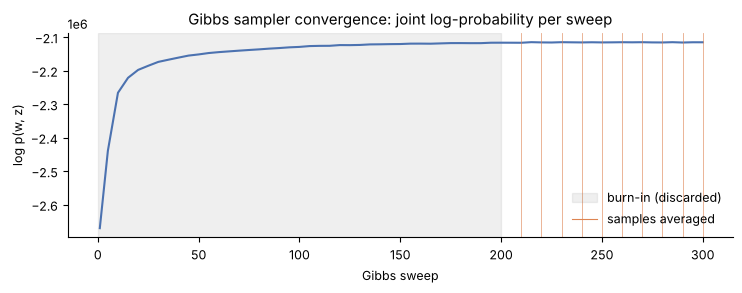

log p(w, z): -2,670,190 after sweep 1 -> -2,151,684 after sweep 50 -> -2,115,420 after sweep 300
change over the last 100 sweeps: 0.059% of the value


In [16]:
tr_it, tr_ll = zip(*trace)
fig, ax = plt.subplots(figsize=(7.5, 3))
ax.plot(tr_it, tr_ll, color="#4c72b0")
ax.axvspan(0, BURN_IN, color="grey", alpha=0.12, label="burn-in (discarded)")
for s in range(BURN_IN + THIN, N_ITER + 1, THIN):
    ax.axvline(s, color="#dd8452", lw=0.6, alpha=0.7)
ax.plot([], [], color="#dd8452", lw=0.8, label="samples averaged")
ax.set_xlabel("Gibbs sweep"); ax.set_ylabel("log p(w, z)")
ax.set_title("Gibbs sampler convergence: joint log-probability per sweep"); ax.legend(frameon=False, loc="lower right")
plt.tight_layout(); fig.savefig(OUT / "gibbs_trace.png", dpi=200, bbox_inches="tight"); plt.show()
early = [ll for it, ll in trace if it <= 50]
print(f"log p(w, z): {trace[0][1]:,.0f} after sweep 1 -> {early[-1]:,.0f} after sweep 50 -> {trace[-1][1]:,.0f} after sweep {N_ITER}")
print(f"change over the last 100 sweeps: {abs(trace[-1][1] - dict(trace)[N_ITER - 100]) / abs(trace[-1][1]):.3%} of the value")

### Variational Bayes vs. Gibbs sampling

Topic numbers are arbitrary in both methods (*label switching*), so before comparing, each Gibbs topic is matched one-to-one to a VB topic. The matching uses the Hungarian algorithm on the **Jensen–Shannon distance** between their word distributions. JS distance is 0 for identical distributions and 1 for distributions with no words in common.

In [17]:
def js_distance_matrix(P, Q):
    M = (P[:, None, :] + Q[None, :, :]) / 2
    kl = lambda A, Bm: np.sum(A * np.log2(A / Bm), axis=-1)
    return np.sqrt((kl(P[:, None, :], M) + kl(Q[None, :, :], M)) / 2)

JS = js_distance_matrix(phi_vb, phi_gs)
_, match = linear_sum_assignment(JS)              # VB topic k  <->  Gibbs topic match[k]
labels_gs = label_topics(phi_gs)
q_gs = topic_quality(phi_gs)
theta_gs_obs = fold_in(phi_gs, obs_half, ALPHA)

cmp_rows = []
for k in np.argsort(-prev_vb):
    g = match[k]
    ov = len(set(top_ids(phi_vb)[k]) & set(top_ids(phi_gs)[g]))
    cmp_rows.append({"VB topic": f"T{k} {labels_vb[k]}", "Gibbs topic": f"T{g} {labels_gs[g]}", "JS distance": round(JS[k, g], 3),
                     "shared top-10 words": ov, "Gibbs top words": ", ".join(vocab[top_ids(phi_gs)[g][:8]])})
CMP = pd.DataFrame(cmp_rows)
display(CMP)

dom_vb, dom_gs = theta_vb.argmax(1), np.argsort(match)[theta_gs.argmax(1)]   # Gibbs topics renamed to VB numbering
theta_corr = np.mean([np.corrcoef(theta_vb[:, k], theta_gs[:, match[k]])[0, 1] for k in range(K_FINAL)])
METHODS = pd.DataFrame({
    "variational Bayes (scikit-learn)": [round(q_vb["npmi"], 3), round(q_vb["diversity"], 2),
                                         round(completion_perplexity(phi_vb, vb.transform(X_obs)), 1), round(VB_SECONDS)],
    "collapsed Gibbs sampling (own code)": [round(q_gs["npmi"], 3), round(q_gs["diversity"], 2),
                                            round(completion_perplexity(phi_gs, theta_gs_obs), 1), round(GS_SECONDS)]},
    index=["NPMI coherence", "topic diversity", "held-out perplexity", "training time (s)"])
display(METHODS)
print(f"Same dominant topic for {np.mean(dom_vb == dom_gs):.1%} of training documents; "
      f"mean correlation of matched θ columns {theta_corr:.3f}; mean JS distance of matched topics {JS[np.arange(K_FINAL), match].mean():.3f}")
pd.DataFrame([{"topic": k, "label": labels_gs[k], "rank": r + 1, "word": vocab[i], "probability": round(phi_gs[k, i], 5)}
              for k, ids in enumerate(top_ids(phi_gs, 20)) for r, i in enumerate(ids)]).to_csv(OUT / "topic_words_gibbs.csv", index=False)
print("saved outputs/topic_words_gibbs.csv")

,VB topic,Gibbs topic,JS distance,shared top-10 words,Gibbs top words
0,T2 Economy & markets,T4 Economy & markets,0.294,7,"company, rise, sale, market, firm, economy, share, bank"
1,T1 Sport,T3 Sport,0.235,9,"win, game, play, player, england, team, match, club"
2,"T3 Entertainment: film, music & TV","T5 Entertainment: film, music & TV",0.366,8,"film, award, star, win, music, director, actor, play"
3,T0 UK politics & elections,T1 UK politics & elections,0.333,8,"government, labour, party, plan, election, blair, issue, country"
4,T4 Internet & mobile tech,T2 Internet & mobile tech,0.366,9,"technology, game, service, mobile, user, computer, network, net"
5,"T5 Law, courts & civil liberties","T0 Law, courts & civil liberties",0.487,8,"court, law, case, charge, police, company, claim, yukos"


,variational Bayes (scikit-learn),collapsed Gibbs sampling (own code)
NPMI coherence,0.259,0.228
topic diversity,0.930,0.920
held-out perplexity,1990.400,1885.200
training time (s),35.000,144.000


Same dominant topic for 88.9% of training documents; mean correlation of matched θ columns 0.913; mean JS distance of matched topics 0.347
saved outputs/topic_words_gibbs.csv


## 8. Interpreting the topics against the BBC sections

The BBC's five section labels were not seen during training. Here they are compared with the topics, to show what LDA discovered beyond those labels:
* **heat map:** the average θ of each topic in the documents of each section;
* **NMI and ARI:** agreement between each document's *dominant topic* and its section (1 = perfect agreement, 0 = chance). With more topics than sections, NMI is the fairer of the two, because splitting a section into sub-topics lowers ARI even when the topics are good;
* **intertopic distance map:** the topics placed in 2-D by classical multidimensional scaling of their JS distances, with bubble area showing topic prevalence (the idea behind LDAvis).

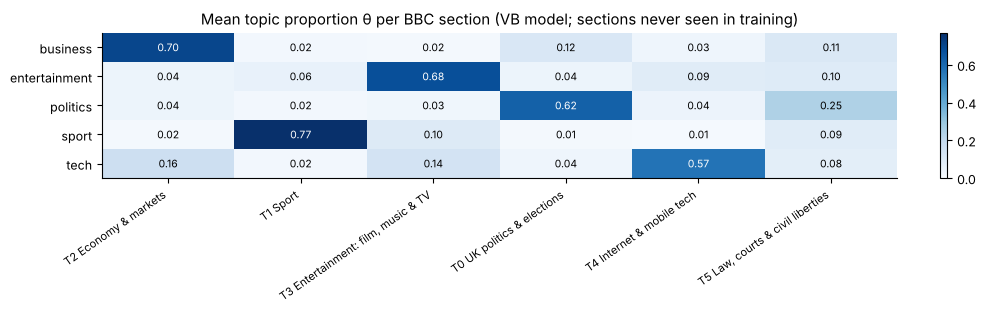

,VB dominant topic,Gibbs dominant topic
NMI,0.710,0.776
ARI,0.728,0.811
purity,0.879,0.915


Section where each topic is concentrated:
  T2 Economy & markets                   -> business (73% of its weight)
  T1 Sport                               -> sport (87% of its weight)
  T3 Entertainment: film, music & TV     -> entertainment (71% of its weight)
  T0 UK politics & elections             -> politics (75% of its weight)
  T4 Internet & mobile tech              -> tech (77% of its weight)
  T5 Law, courts & civil liberties       -> politics (40% of its weight)


In [18]:
sections = sorted(corpus.category.unique())
order = np.argsort(-prev_vb)
heat = pd.DataFrame([theta_vb[tr.category.values == s].mean(0)[order] for s in sections], index=sections,
                    columns=[f"T{k} {labels_vb[k]}" for k in order])
fig, ax = plt.subplots(figsize=(10, 3.2))
im = ax.imshow(heat.values, cmap="Blues", aspect="auto", vmin=0)
ax.set_xticks(range(K_FINAL)); ax.set_xticklabels(heat.columns, rotation=35, ha="right", fontsize=8)
ax.set_yticks(range(len(sections))); ax.set_yticklabels(sections)
for i in range(len(sections)):
    for j in range(K_FINAL):
        v = heat.values[i, j]
        ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=7.5, color="white" if v > 0.45 else "black")
ax.set_title("Mean topic proportion θ per BBC section (VB model; sections never seen in training)")
plt.colorbar(im, ax=ax, fraction=0.02); plt.tight_layout()
fig.savefig(OUT / "topics_vs_sections.png", dpi=200, bbox_inches="tight"); plt.show()

def agreement(dom):
    major = {k: tr.category[dom == k].mode()[0] for k in np.unique(dom)}
    return {"NMI": round(float(normalized_mutual_info_score(tr.category, dom)), 3), "ARI": round(float(adjusted_rand_score(tr.category, dom)), 3),
            "purity": round(float(np.mean([major[k] == c for k, c in zip(dom, tr.category)])), 3)}
AGREE = pd.DataFrame({"VB dominant topic": agreement(dom_vb), "Gibbs dominant topic": agreement(dom_gs)})
display(AGREE)
home = {f"T{k} {labels_vb[k]}": f"{heat.iloc[:, j].idxmax()} ({heat.iloc[:, j].max() / heat.iloc[:, j].sum():.0%} of its weight)"
        for j, k in enumerate(order)}
print("Section where each topic is concentrated:")
for t, s in home.items():
    print(f"  {t:<38} -> {s}")

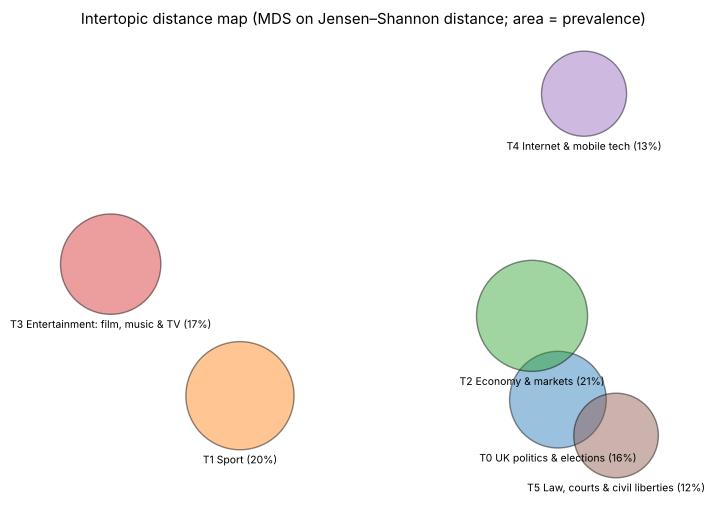

In [19]:
D_js = js_distance_matrix(phi_vb, phi_vb)
def classical_mds(D, dims=2):
    """Classical (Torgerson) multidimensional scaling of a distance matrix."""
    n = len(D); J = np.eye(n) - np.ones((n, n)) / n
    vals, vecs = np.linalg.eigh(-0.5 * J @ (D ** 2) @ J)
    top = np.argsort(vals)[::-1][:dims]
    return vecs[:, top] * np.sqrt(np.maximum(vals[top], 0))
xy = classical_mds(D_js)
fig, ax = plt.subplots(figsize=(7.5, 5.2))
ax.scatter(xy[:, 0], xy[:, 1], s=prev_vb * 30000, alpha=0.45, c=[plt.cm.tab10(k % 10) for k in range(K_FINAL)], edgecolors="k")
for k in range(K_FINAL):
    ax.annotate(f"T{k} {labels_vb[k]} ({prev_vb[k]:.0%})", xy[k], ha="center", va="center", fontsize=7.5,
                xytext=(0, -np.sqrt(prev_vb[k] * 30000) / 2 - 7), textcoords="offset points")
for sp_ in ax.spines.values():
    sp_.set_visible(False)
ax.set_title("Intertopic distance map (MDS on Jensen–Shannon distance; area = prevalence)")
ax.set_xticks([]); ax.set_yticks([]); ax.margins(0.18)
plt.tight_layout(); fig.savefig(OUT / "intertopic_map.png", dpi=200, bbox_inches="tight"); plt.show()

## 9. Stability: are the topics reproducible?

LDA's objective has many local optima, so a topic is only worth interpreting if it comes back when training is repeated. The VB model is refitted with two more random seeds and each new topic is matched to the seed-0 topics. The Gibbs topics from §7 serve as a third check, made with a completely different inference algorithm.

In [20]:
stab = {f"T{k} {labels_vb[k]}": {} for k in order}
unstable = []
for s in [1, 2]:
    m_s = LatentDirichletAllocation(n_components=K_FINAL, doc_topic_prior=ALPHA, topic_word_prior=BETA,
                                    learning_method="batch", max_iter=100, random_state=s).fit(X_train)
    phi_s = normalise(m_s.components_)
    _, mt = linear_sum_assignment(js_distance_matrix(phi_vb, phi_s))
    for k in order:
        ov = len(set(top_ids(phi_vb)[k]) & set(top_ids(phi_s)[mt[k]]))
        stab[f"T{k} {labels_vb[k]}"][f"VB seed {s}"] = ov
        if ov < 5:
            unstable.append((s, labels_vb[k], ", ".join(vocab[top_ids(phi_s)[mt[k]]])))
for k in order:
    stab[f"T{k} {labels_vb[k]}"]["Gibbs"] = len(set(top_ids(phi_vb)[k]) & set(top_ids(phi_gs)[match[k]]))
STAB = pd.DataFrame(stab).T
print("Shared top-10 words with the seed-0 VB topic (10 = identical top-10 list):")
display(STAB)
print(f"mean overlap: VB seeds {STAB[['VB seed 1', 'VB seed 2']].values.mean():.1f}/10, Gibbs {STAB['Gibbs'].mean():.1f}/10; "
      f"topics with overlap >= 6 in all three runs: {(STAB.min(axis=1) >= 6).sum()} of {K_FINAL}")
for s, lab, words in unstable:
    print(f"\nseed {s} has no '{lab}' topic; its closest topic instead is: {words}")

Shared top-10 words with the seed-0 VB topic (10 = identical top-10 list):


,VB seed 1,VB seed 2,Gibbs
T2 Economy & markets,8,8,7
T1 Sport,8,9,9
"T3 Entertainment: film, music & TV",7,9,8
T0 UK politics & elections,7,7,8
T4 Internet & mobile tech,8,9,9
"T5 Law, courts & civil liberties",1,6,8


mean overlap: VB seeds 7.2/10, Gibbs 8.2/10; topics with overlap >= 6 in all three runs: 5 of 6

seed 1 has no 'Law, courts & civil liberties' topic; its closest topic instead is: win, world, final, man, play, woman, trial, charge, title, british


## 10. What if *K* equals the number of sections? (*K* = 5)

There are five BBC sections, so *K* = 5 might look like the natural choice. The *K* = 5 model from the sweep in §5 shows what LDA does with only five topics.

In [21]:
m5 = models[5]
phi5, theta5 = normalise(m5.components_), m5.transform(X_train)
lab5 = label_topics(phi5)
heat5 = pd.DataFrame([theta5[tr.category.values == s].mean(0) for s in sections], index=sections,
                     columns=[f"T{k} {lab5[k]}" for k in range(5)]).round(2)
print("K = 5 topics (top 10 words):")
for k, ids in enumerate(top_ids(phi5)):
    print(f"  T{k} {lab5[k]:<32} {', '.join(vocab[ids])}")
print("\nMean θ per section:")
display(heat5)
print("agreement with sections:", agreement(theta5.argmax(1)))

K = 5 topics (top 10 words):
  T0 UK politics & elections          government, labour, party, plan, election, blair, country, issue, minister, claim
  T1 Sport                            win, play, game, player, england, club, match, team, final, half
  T2 Economy & markets                company, firm, market, rise, sale, share, bank, business, analyst, growth
  T3 Entertainment: film, music & TV  film, game, win, award, star, music, play, world, director, record
  T4 Internet & mobile tech           technology, service, mobile, user, computer, network, phone, net, site, information

Mean θ per section:


,T0 UK politics & elections,T1 Sport,T2 Economy & markets,"T3 Entertainment: film, music & TV",T4 Internet & mobile tech
business,0.15,0.02,0.77,0.02,0.05
entertainment,0.08,0.05,0.05,0.72,0.11
politics,0.83,0.02,0.05,0.03,0.07
sport,0.03,0.77,0.05,0.13,0.02
tech,0.06,0.02,0.22,0.15,0.56


agreement with sections: {'NMI': 0.729, 'ARI': 0.75, 'purity': 0.887}


## 11. Findings, limitations and possible extensions

**What the topics mean.** With *K* = 6, LDA found six themes that a reader can name from their top words alone:
* **Economy & markets** (company, firm, market, rise, share, bank);
* **Sport** (win, play, player, England, club, match);
* **Entertainment** (film, award, star, music, actor);
* **UK politics** (Labour, government, election, Blair, Brown, prime_minister);
* **Internet & mobile technology** (technology, mobile, user, network, phone);
* **Law & courts** (law, court, case, police, charge, ban).

Five of them line up with one BBC section, carrying 71–87% of their weight there. The sixth, **law & courts**, is the interesting one. It belongs to no single section: it collects crime and justice stories filed under politics (home-office policy, sentencing), legal battles in business (the Yukos bankruptcy case, EU passenger rights) and court cases in other sections. LDA discovers *themes in the words*, not the newsroom's filing system, and this topic shows the difference.

**Two inference methods, one model.**
* Variational Bayes and collapsed Gibbs sampling recovered essentially the **same six topics**: every matched pair shares 7–9 of its top-10 words. 89% of documents get the same dominant topic from both, and the matched topic proportions correlate at about 0.91.
* VB is about 4× faster and gives slightly more coherent top-word lists (NPMI 0.259 vs 0.228).
* Gibbs predicts held-out words better (perplexity 1,885 vs 1,990), and its dominant topics agree more closely with the BBC sections (NMI 0.78 vs 0.71). VB's fully factorised approximation is known to be biased, whereas the sampler, given enough sweeps, draws from the true posterior. The trade-off is speed against accuracy.

**Why *K* = 6 rather than 5.**
* There are five sections, and the *K* = 5 model does reproduce them (NMI 0.73).
* But its coherence varies widely between random seeds (NPMI 0.16–0.25), and tech articles put only 56% of their weight on the tech topic, with the rest leaking into business and entertainment.
* *K* = 6 had the best and most consistent coherence over three seeds, and the extra topic is a genuine cross-cutting theme rather than a duplicate.
* Larger *K* improves perplexity but lowers coherence and diversity: it splits topics into overlapping fragments.

**Stability.**
* Five of the six topics come back in every VB seed and in the Gibbs run.
* The law & courts topic is the least stable: one VB seed replaced it with a second sport topic (individual sports such as athletics and tennis, together with words such as *trial* and *charge*).
* So it should be presented as a real but weaker theme, and conclusions should rest on topics that survive several runs.

**Limitations.**
* LDA is a bag-of-words model: word order, negation and context are lost.
* Polysemous words are shared between topics: *game* appears in sport, in entertainment and in technology (video games).
* Topic labels are human interpretations of word lists. The cue-word labeller only standardises them.
* NPMI is computed on the same corpus the models were trained on, not on an external reference corpus such as Wikipedia.
* Results depend on preprocessing choices: the news-generic stop list, `min_df`/`max_df` and phrase thresholds.
* The sampler is pure Python (about 0.5 s per sweep here). That is fine for a 2,000-document corpus but too slow for millions of documents.

**Possible extensions.**
* Vectorised or Cython/Numba Gibbs sampling, and online VB for large corpora.
* An asymmetric or learnt α (topics differ in prevalence).
* Coherence against an external reference corpus.
* Interactive LDAvis/pyLDAvis exploration.
* Dynamic topic models to follow how themes change over 2004–2005.
* Neural or embedding-based topic models (BERTopic, ProdLDA) as a comparison.